# Méthode de quasi-Newton (BFGS)

Même fonction que dans les deux autres notebooks. On remplace l'inverse du hessien par une approximation H_k mise à jour avec la formule BFGS :

d_k = -H_k grad f(x_k)

H_{k+1} = (I - rho s y^T) H_k (I - rho y s^T) + rho s s^T

avec s = x_{k+1} - x_k, y = grad f(x_{k+1}) - grad f(x_k) et rho = 1 / (y^T s).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# fonction de Rosenbrock (meme fonction dans les trois notebooks)
def f(x):
    return (1 - x[0])**2 + 100*(x[1] - x[0]**2)**2

def grad_f(x):
    return np.array([
        -2*(1 - x[0]) - 400*x[0]*(x[1] - x[0]**2),
        200*(x[1] - x[0]**2)
    ])

x0 = np.array([-1.2, 1.0])   # point de depart
x_etoile = np.array([1.0, 1.0])  # minimum connu, f(x*) = 0
tol = 1e-6
max_iter = 50000

In [2]:
def backtracking(x, g, d, alpha0=1.0, rho=0.5, c=1e-4):
    alpha = alpha0
    fx = f(x)
    pente = g @ d
    while f(x + alpha*d) > fx + c*alpha*pente:
        alpha *= rho
        if alpha < 1e-16:
            break
    return alpha

def bfgs(x0, tol, max_iter):
    n = len(x0)
    x = x0.copy()
    H = np.eye(n)
    g = grad_f(x)
    hist_x = [x.copy()]
    hist_f = [f(x)]
    for k in range(max_iter):
        if np.linalg.norm(g) < tol:
            break
        d = -H @ g
        alpha = backtracking(x, g, d)
        x_new = x + alpha * d
        g_new = grad_f(x_new)
        s = x_new - x
        y = g_new - g
        sy = s @ y
        # on ne met a jour H que si la condition de courbure est verifiee
        if sy > 1e-10:
            r = 1.0 / sy
            I = np.eye(n)
            H = (I - r*np.outer(s, y)) @ H @ (I - r*np.outer(y, s)) + r*np.outer(s, s)
        x, g = x_new, g_new
        hist_x.append(x.copy())
        hist_f.append(f(x))
    return x, k, np.array(hist_x), np.array(hist_f), H

In [3]:
x_fin, nb_iter, hist_x, hist_f, H = bfgs(x0, tol, max_iter)

print("iterations :", nb_iter)
print("x final :", x_fin)
print("f(x final) :", f(x_fin))
print("norme du gradient :", np.linalg.norm(grad_f(x_fin)))

iterations : 34
x final : [1.         0.99999999]
f(x final) : 2.745638889488571e-17
norme du gradient : 8.834638033449345e-08


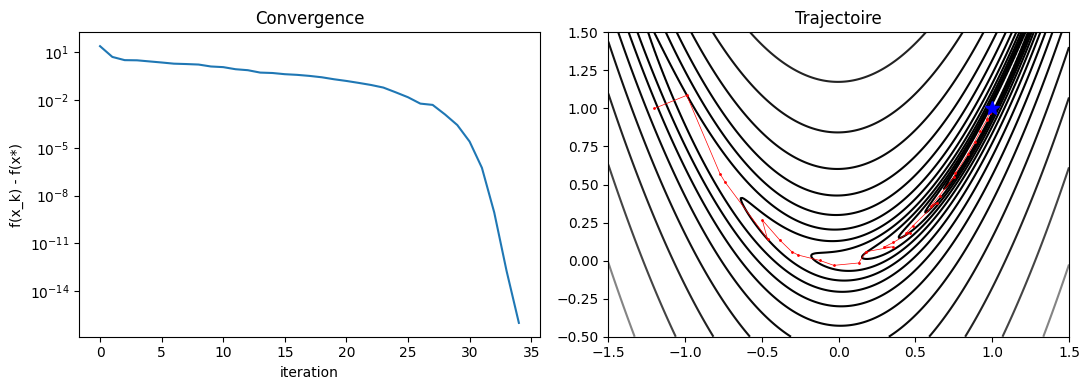

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].semilogy(np.maximum(hist_f, 1e-16))
ax[0].set_xlabel("iteration")
ax[0].set_ylabel("f(x_k) - f(x*)")
ax[0].set_title("Convergence")

X, Y = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-0.5, 1.5, 300))
Z = (1 - X)**2 + 100*(Y - X**2)**2
ax[1].contour(X, Y, Z, levels=np.logspace(-1, 3, 15), cmap="gray")
ax[1].plot(hist_x[:, 0], hist_x[:, 1], "r.-", lw=0.5, ms=2)
ax[1].plot(*x_etoile, "b*", ms=10)
ax[1].set_title("Trajectoire")

plt.tight_layout()
plt.show()

Vérification : en fin d'algorithme H doit être proche de l'inverse du hessien au minimum.

In [5]:
hess = np.array([[2 - 400*(x_etoile[1] - 3*x_etoile[0]**2), -400*x_etoile[0]],
                 [-400*x_etoile[0], 200]])
print("H final :")
print(H)
print("inverse du hessien en x* :")
print(np.linalg.inv(hess))

H final :
[[0.49481689 0.98940332]
 [0.98940332 1.98333465]]
inverse du hessien en x* :
[[0.5   1.   ]
 [1.    2.005]]
